# Librerías

In [27]:
from pathlib import Path
import pandas as pd

import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.cluster import MiniBatchKMeans
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Conjunto de datos

Para el desarrollo de este proyecto se construyó un conjunto de datos de imágenes destinado a una tarea de clasificación binaria, cuyo objetivo es distinguir entre motocicletas y bicicletas.

El dataset está compuesto por un total de 121 imágenes, distribuidas de manera equilibrada en dos clases:

- Clase Motocicletas: 61 imágenes.
- Clase Bicicletas: 60 imágenes.

Se decidió utilizar la misma cantidad de imágenes por clase para mantener un conjunto de datos balanceado y evitar que alguna categoría tuviera una mayor representación durante el entrenamiento del modelo.



In [2]:

DATASET_DIR = Path("dataset")

clases = ["motocicletas", "bicicletas" ] #Guardamos las imagenes en una carpeta y las descargamos
                                        # Esto para en caso de que los URLs expiren y afecten el modelo y el laboratorio

images_rgb = []
labels = []
rutas_imagenes = []

for clase in clases:
    carpeta = DATASET_DIR / clase

    if not carpeta.exists():
        raise FileNotFoundError(
            f"No se encontró la carpeta: {carpeta}"
        )

    for ruta in sorted(carpeta.iterdir()):

        if ruta.suffix.lower() not in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            continue

        img_bgr = cv2.imread(str(ruta))

        if img_bgr is None:
            print("Imagen no válida:", ruta)
            continue

        img_rgb = cv2.cvtColor(
            img_bgr,
            cv2.COLOR_BGR2RGB
        )

        images_rgb.append(img_rgb)
        labels.append(clase)
        rutas_imagenes.append(str(ruta))

images_rgb = list(images_rgb)
labels = np.array(labels)

print("Total de imágenes:", len(images_rgb))
print("\nDistribución por clase:")
print(pd.Series(labels).value_counts())

Total de imágenes: 121

Distribución por clase:
motocicletas    61
bicicletas      60
Name: count, dtype: int64


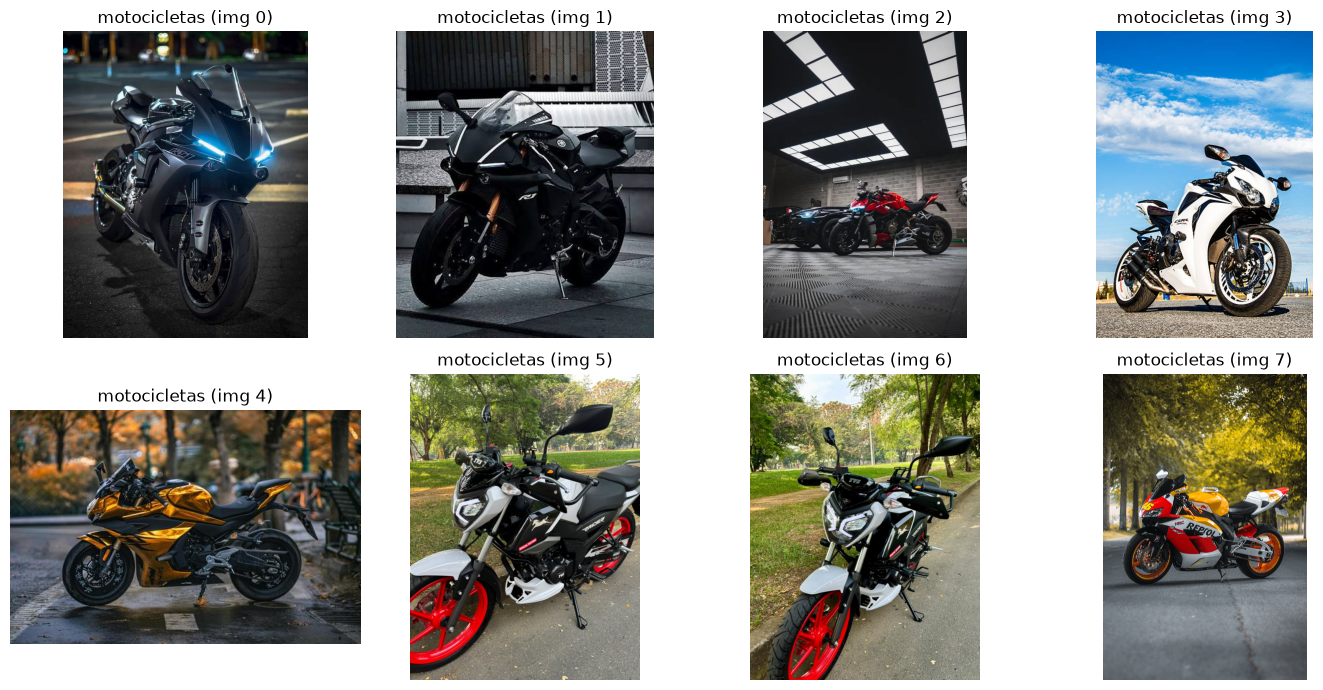

In [3]:
# Mostramos 8 imágenes de motocicletas del dataset
idx_motos = [i for i, lab in enumerate(labels) if lab == "motocicletas"]
n = min(8, len(idx_motos))

plt.figure(figsize=(14, 7))

for k, i in enumerate(idx_motos[:n]):
    plt.subplot(2, 4, k + 1)
    plt.imshow(images_rgb[i])
    plt.title(f"{labels[i]} (img {i})")
    plt.axis("off")

plt.tight_layout()
plt.show()

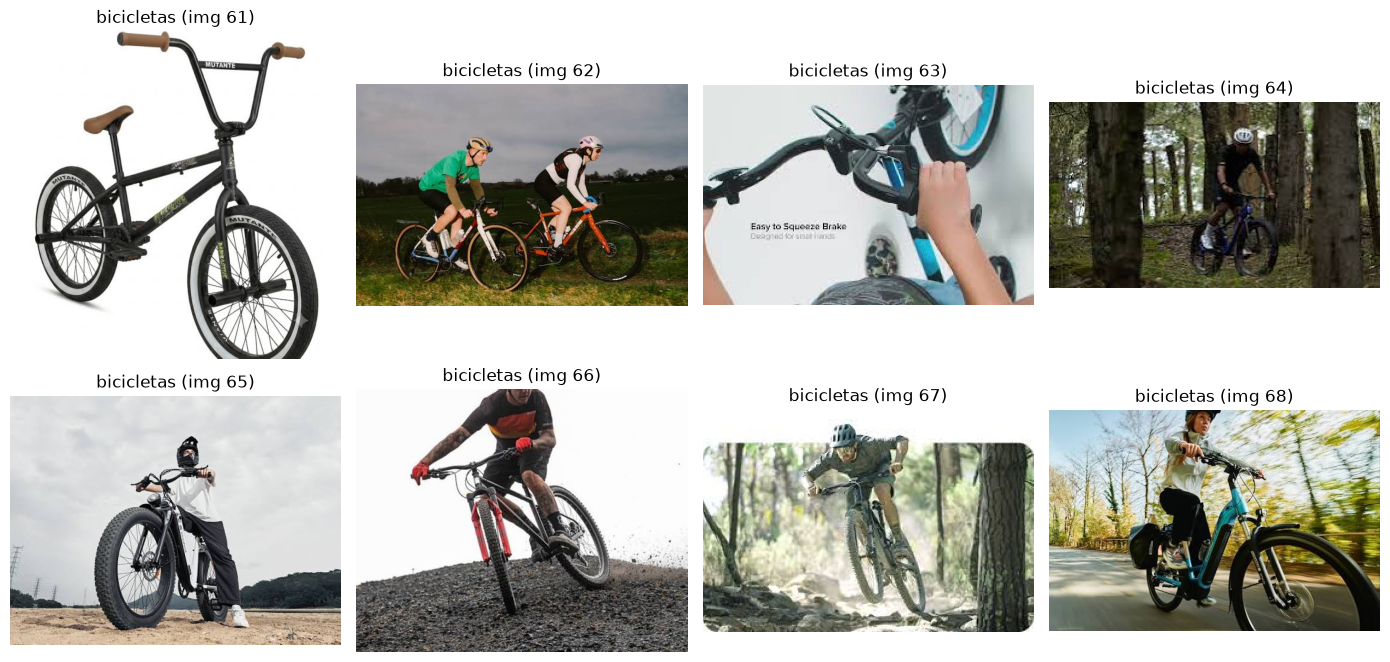

In [4]:
# Mostramos 8 imágenes de bicicletas
idx_bicis = [i for i, lab in enumerate(labels) if lab == "bicicletas"]
n = min(8, len(idx_bicis))

plt.figure(figsize=(14, 7))

for k, i in enumerate(idx_bicis[:n]):
    plt.subplot(2, 4, k + 1)
    plt.imshow(images_rgb[i])
    plt.title(f"{labels[i]} (img {i})")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Extracción de características

## Algoritmos SIFT

Keypoints por imagen: [1909, 1003, 1761, 1610, 1609, 15628, 17030, 27486, 683, 5040, 1494, 1664, 7710, 1452, 3592, 1676, 10535, 9901, 2043, 1917, 1075, 1197, 2242, 3287, 3733, 3594, 3805, 1898, 1858, 20698, 28452, 734, 6029, 1208, 1815, 336, 811, 1676, 1516, 735, 840, 1339, 478, 617, 861, 1231, 6188, 2638, 6809, 5827, 19188, 699, 4246, 6091, 13078, 4578, 1546, 8731, 572, 576, 675, 942, 1166, 254, 530, 916, 1680, 802, 2051, 2082, 249, 889, 1044, 840, 1901, 1682, 439, 637, 3508, 2622, 1619, 539, 2826, 680, 613, 776, 2014, 193, 1282, 264, 887, 217, 693, 1304, 876, 3076, 255, 1493, 550, 288, 1622, 500, 2872, 743, 1224, 2771, 983, 3801, 1111, 3207, 861, 910, 601, 1786, 1317, 6465, 178, 3878, 1907, 982, 839]


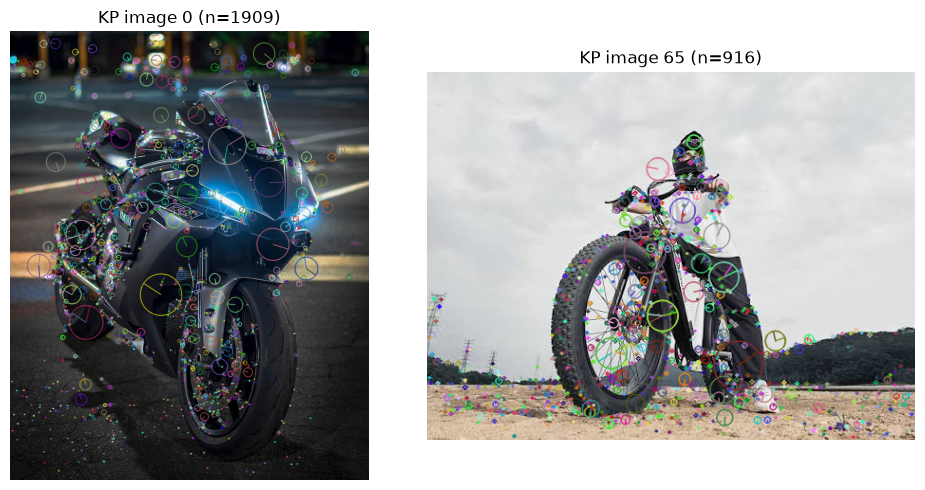

In [5]:
np.random.seed(42)
sift = cv2.SIFT_create()

images_gray = []
all_desc_list = []   # Descriptores
n_keypoints = []

for img_rgb in images_rgb:
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    images_gray.append(gray)
    keypoints, descriptors = sift.detectAndCompute(gray, None) # Detecta puntos y calcula descriptores (SIFT = 128D por keypoint)

    if descriptors is None:
        descriptors = np.zeros((0, 128), dtype=np.float32)

    all_desc_list.append(descriptors)
    n_keypoints.append(len(keypoints))

print("Keypoints por imagen:", n_keypoints)


plt.figure(figsize=(10,5)) # Dónde aparece SIFT

for i, idx in enumerate([0, 65]):  # 0 es una moto y 65 cae dentro del rango de las bicis (61 al 90)
    
    img_kp = cv2.drawKeypoints(images_rgb[idx], sift.detect(images_gray[idx], None), None,
                               flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    plt.subplot(1,2,i+1); plt.imshow(img_kp); plt.title(f"KP image {idx} (n={n_keypoints[idx]})"); plt.axis('off')

plt.tight_layout(); plt.show()


## Algoritmo ORB

#### Justificación

Se seleccionó el algoritmo **ORB (Oriented FAST and Rotated BRIEF)** como alternativa a SIFT porque permite extraer características de las imágenes en menos tiempo y utilizando menos memoria. Resulta interesante comparar ambos algoritmos para conocer si estas ventajas de ORB afectan la precisión de la clasificación o si es posible obtener resultados similares con un menor costo computacional. Así, se busca comprender mejor las diferencias entre los dos métodos y cómo influyen en los resultados del modelo.

Keypoints ORB por imagen: [10338, 5674, 10235, 10961, 5863, 57761, 71511, 78301, 4683, 42261, 5749, 10736, 38424, 8013, 32152, 7718, 44167, 39368, 8551, 9738, 7541, 5445, 9182, 22745, 17530, 17595, 15637, 8259, 7541, 66656, 63401, 5667, 18095, 5254, 6758, 2389, 5865, 6273, 5549, 4517, 4916, 5690, 1311, 2417, 4011, 5732, 40776, 20436, 19966, 14878, 69617, 1818, 22302, 29577, 43565, 23081, 9868, 28349, 3354, 3318, 3057, 6527, 5063, 782, 1264, 4755, 9178, 2010, 11102, 8035, 1545, 5177, 7385, 3047, 7716, 7217, 2000, 1690, 9909, 10381, 4730, 2059, 9029, 1213, 5468, 3984, 12370, 1351, 6789, 1006, 8833, 1233, 4246, 5161, 7948, 11556, 1209, 8490, 3393, 1883, 11038, 2439, 16005, 5380, 7963, 12770, 4772, 16388, 2726, 12591, 6064, 4242, 4623, 6650, 5511, 33195, 1278, 15661, 7935, 3781, 5329]


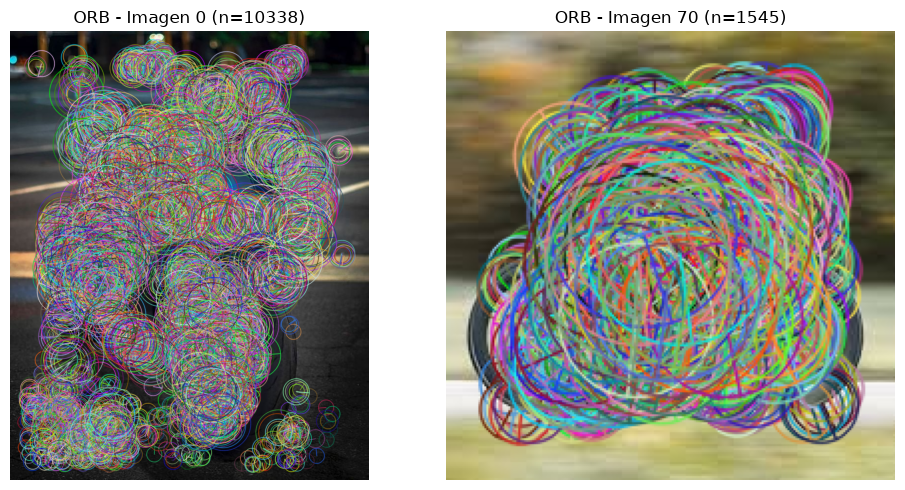

In [13]:

# Crear el detector ORB
orb = cv2.ORB_create(nfeatures=100000)

images_gray_orb = []
all_desc_list_orb = []   # Descriptores ORB
n_keypoints_orb = []

for img_rgb in images_rgb:

    # Convertir la imagen a escala de grises
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    images_gray_orb.append(gray)

    # Detectar puntos clave y calcular descriptores ORB
    keypoints, descriptors = orb.detectAndCompute(gray, None)

    # Si no se detectan descriptores, crear un arreglo vacío
    if descriptors is None:
        descriptors = np.zeros((0, 32), dtype=np.uint8)

    # Guardar los descriptores y la cantidad de puntos clave
    all_desc_list_orb.append(descriptors)
    n_keypoints_orb.append(len(keypoints))

print("Keypoints ORB por imagen:", n_keypoints_orb)


# Visualizar los puntos clave detectados por ORB
plt.figure(figsize=(10, 5))

for i, idx in enumerate([0, 70]):

    img_kp = cv2.drawKeypoints(
        images_rgb[idx],
        orb.detect(images_gray_orb[idx], None),
        None,
        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
    )

    plt.subplot(1, 2, i + 1)
    plt.imshow(img_kp)
    plt.title(f"ORB - Imagen {idx} (n={n_keypoints_orb[idx]})")
    plt.axis("off")

plt.tight_layout()
plt.show()


#### - ANÁLISIS

Al observar los resultados, se encontraron diferencias en la cantidad y distribución de los puntos clave detectados. En el ejemplo de la imagen 0, correspondiente a la clase de motocicletas y analizada con ambos extractores, SIFT identificó 1.909 puntos con un tiempo mucho más largo, mientras que ORB detectó 10.338 pero en un tiempo muy corto.

ORB mostró una mayor concentración de puntos en determinadas partes de la motocicleta, especialmente en zonas con cambios de contraste y detalles estructurales. Por su parte, SIFT presentó una distribución más amplia, identificando características en componentes como las ruedas, el motor y la carrocería, pero también en algunas regiones del fondo. Esto sugiere que SIFT logra capturar una mayor variedad de detalles visuales, aunque no todos necesariamente aportan información útil para distinguir entre motocicletas y bicicletas.

Respecto al tipo de regiones detectadas, ORB se enfoca principalmente en esquinas y cambios de intensidad, mientras que SIFT identifica estructuras distintivas a diferentes escalas. Esta diferencia, junto con la configuración de cada algoritmo, podría explicar por qué SIFT encuentra más puntos en detalles pequeños y zonas con texturas variadas. Además hay que considerar que ORB podría estar limitado a un máximo de características, lo que también influiría en la diferencia observada.

# Construcción de diccionario/vocabulario

In [14]:
# Separar las imágenes en entrenamiento y prueba

indices = np.arange(len(images_rgb))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.40,
    random_state=42,
    stratify=labels
)

print("Imágenes de entrenamiento:", len(train_idx))
print("Imágenes de prueba:", len(test_idx))

Imágenes de entrenamiento: 72
Imágenes de prueba: 49


In [15]:
# Reunir descriptores SIFT únicamente de las imágenes de entrenamiento

desc_stack = []

for i in train_idx:

    desc = all_desc_list[i]

    # Muestreo de máximo 400 descriptores por imagen
    if len(desc) > 400:
        idx = np.random.choice(
            len(desc),
            400,
            replace=False
        )
        desc = desc[idx]

    if len(desc) > 0:
        desc_stack.append(desc)

if len(desc_stack) == 0:
    raise RuntimeError(
        "No hay descriptores SIFT en las imágenes de entrenamiento."
    )

# Unir los descriptores en una sola matriz
desc_stack = np.vstack(desc_stack).astype(np.float32)

print("Descriptores de entrenamiento:", desc_stack.shape)

# Construir el diccionario visual
K = 120

kmeans = MiniBatchKMeans(
    n_clusters=K,
    random_state=42,
    batch_size=2048,
    n_init="auto"
)

kmeans.fit(desc_stack)

centers = kmeans.cluster_centers_

print("Diccionario visual entrenado.")
print("Forma de los centros:", centers.shape)

Descriptores de entrenamiento: (28037, 128)
Diccionario visual entrenado.
Forma de los centros: (120, 128)


# Cuantificación vectorial

X (BoVW): (121, 120)  y: (121,)   (K = 120 )


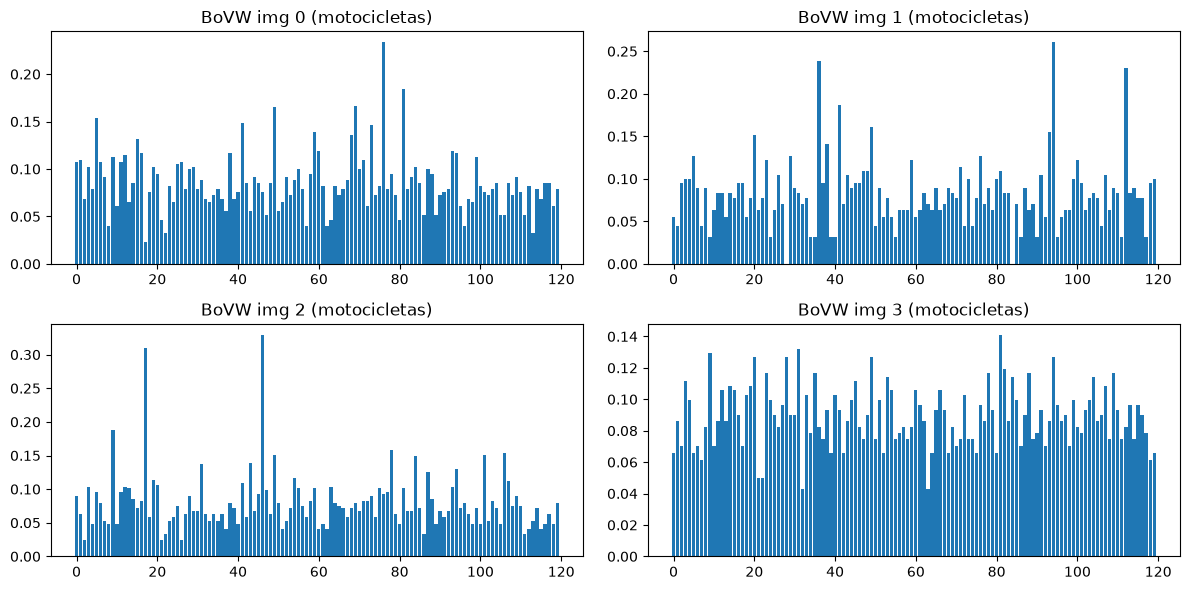

In [16]:
bovw_list = [] # Codifica cada imagen como histograma BoVW

for i, desc in enumerate(all_desc_list):
    if len(desc) == 0:
        hist = np.zeros(K, dtype=np.float32)
    else:
        word_ids = kmeans.predict(desc)             # shape: (num_desc,)
        hist = np.bincount(word_ids, minlength=K)   # cuentas por palabra visual (0..K-1)
        hist = hist.astype(np.float32)

    # Normalización recomendada 
    hist = np.sqrt(hist)
    norm = np.linalg.norm(hist) + 1e-8
    hist = hist / norm

    bovw_list.append(hist)

X = np.vstack(bovw_list)               # shape: (num_imagenes, K)
y = np.array(labels)                  

print("X (BoVW):", X.shape, " y:", y.shape, "  (K =", K, ")")

plt.figure(figsize=(12, 6))

for i in range(4): # Visualización: histogramas BoVW de 4 imágenes
    plt.subplot(2, 2, i+1)
    plt.bar(np.arange(K), X[i])
    plt.title(f"BoVW img {i} ({y[i]})")

plt.tight_layout()  # Puesto fuera del bucle
plt.show()

## Dicionario visual

In [17]:
# Convertir descriptores ORB (32 bytes) a 256 bits en float32
def orb_a_float(desc):
    if len(desc) == 0:
        return np.zeros((0, 256), dtype=np.float32)
    return np.unpackbits(desc, axis=1).astype(np.float32)

all_desc_list_orb_f = [orb_a_float(d) for d in all_desc_list_orb]

# Reunir descriptores ORB únicamente de las imágenes de entrenamiento
np.random.seed(42)
desc_stack_orb = []

for i in train_idx:
    desc = all_desc_list_orb_f[i]

    # Muestreo de máximo 400 descriptores por imagen (igual que en SIFT)
    if len(desc) > 400:
        idx = np.random.choice(len(desc), 400, replace=False)
        desc = desc[idx]

    if len(desc) > 0:
        desc_stack_orb.append(desc)

if len(desc_stack_orb) == 0:
    raise RuntimeError("No hay descriptores ORB en las imágenes de entrenamiento.")

desc_stack_orb = np.vstack(desc_stack_orb).astype(np.float32)
print("Descriptores ORB de entrenamiento:", desc_stack_orb.shape)

K_orb = 120

kmeans_orb = MiniBatchKMeans(
    n_clusters=K_orb,
    random_state=42,
    batch_size=2048,
    n_init="auto"
)
kmeans_orb.fit(desc_stack_orb)

centers_orb = kmeans_orb.cluster_centers_
print("Diccionario visual ORB entrenado.")
print("Forma de los centros:", centers_orb.shape)

Descriptores ORB de entrenamiento: (28800, 256)
Diccionario visual ORB entrenado.
Forma de los centros: (120, 256)


### - Justificación de K



Comprendiendo que valor de k define cuántas palabras visuales tiene el diccionario. Seleciconarlo es una decisión importante dado que si el vocabulario es muy pequeño, el modelo se queda corto, y si es muy grande se aprende las imágenes en lugar de las clases.

Con pocas palabras (ej: k = 25), el k-means mete en el mismo grupo descriptores que no se parecen tanto. Por ejemplo, la llanta de una moto y la de una bicicleta pueden terminar siendo la misma palabra.

Con muchas palabras (ej: k = 400), cada cluster se forma con muy pocos descriptores, y varios terminan representando detalles de una sola imagen. Como solo tenemos 120 imágenes de entrenamiento, el clasificador se aprende esos detalles y luego falla con imágenes nuevas.

Por esta razón se seleccionó un k = 120, un punto medio para capturar lo que distingue a cada clase y cada palabra se construye con descriptores de muchas imágenes distintas, así que representa patrones generales y no casos puntuales.

## Histogramas BoVW con ORB

X_orb (BoVW): (121, 120)  y: (121,)   (K = 120 )


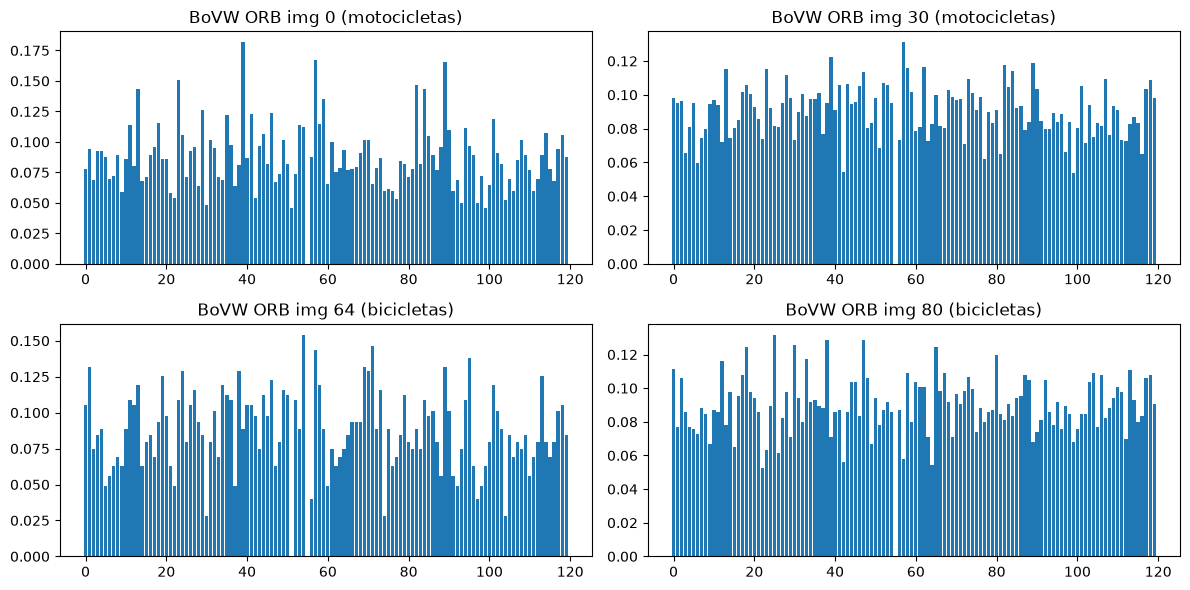

In [ ]:
bovw_list_orb = []

for i, desc in enumerate(all_desc_list_orb_f):
    if len(desc) == 0:
        hist = np.zeros(K_orb, dtype=np.float32)
    else:
        # Asignación dura: cada descriptor -> centro más cercano
        word_ids = kmeans_orb.predict(desc)
        hist = np.bincount(word_ids, minlength=K_orb).astype(np.float32)

    # Normalización power-law + L2 (igual que en SIFT)
    hist = np.sqrt(hist)
    hist = hist / (np.linalg.norm(hist) + 1e-8)

    bovw_list_orb.append(hist)

X_orb = np.vstack(bovw_list_orb)
print("X_orb (BoVW):", X_orb.shape, " y:", y.shape, "  (K =", K_orb, ")")

# Histogramas de 4 imágenes (2 motos y 2 bicis)
ejemplos = [0, 30, 64, 80]

plt.figure(figsize=(12, 6))
for k, i in enumerate(ejemplos):
    plt.subplot(2, 2, k + 1)
    plt.bar(np.arange(K_orb), X_orb[i])
    plt.title(f"BoVW ORB img {i} ({y[i]})")
plt.tight_layout()
plt.show()

# Clasificación (Laboratorio)

Accuracy (SVM lineal): 75.51%

Reporte de clasificación:
               precision    recall  f1-score   support

  bicicletas       0.73      0.79      0.76        24
motocicletas       0.78      0.72      0.75        25

    accuracy                           0.76        49
   macro avg       0.76      0.76      0.76        49
weighted avg       0.76      0.76      0.75        49



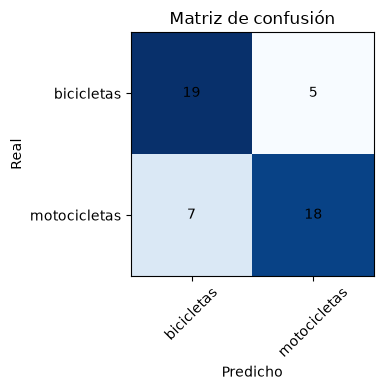

In [22]:
X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

clf = LinearSVC(C=1.0, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)

print("Accuracy (SVM lineal):", f"{acc*100:.2f}%")
print("\nReporte de clasificación:\n", classification_report(y_test, y_pred))

classes = sorted(list(set(y)))
cm = confusion_matrix(y_test, y_pred, labels=classes)

plt.figure(figsize=(4,4))
plt.imshow(cm, cmap='Blues')
plt.title("Matriz de confusión")
plt.xticks(range(len(classes)), classes, rotation=45)
plt.yticks(range(len(classes)), classes)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i,j], ha='center', va='center')

plt.xlabel("Predicho"); plt.ylabel("Real")
plt.tight_layout(); plt.show()


## Clasificador Knn con sift y ORB

Accuracy SIFT + k-NN (k=5): 71.43%

Reporte de clasificación:
               precision    recall  f1-score   support

  bicicletas       0.78      0.58      0.67        24
motocicletas       0.68      0.84      0.75        25

    accuracy                           0.71        49
   macro avg       0.73      0.71      0.71        49
weighted avg       0.73      0.71      0.71        49



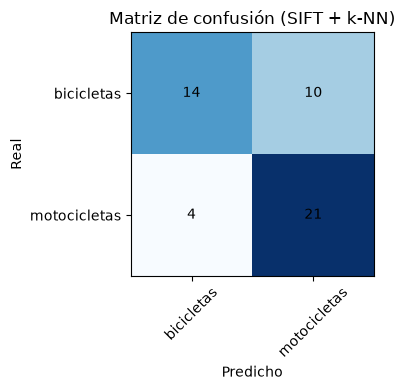

Accuracy ORB + k-NN (k=5): 75.51%

Reporte de clasificación:
               precision    recall  f1-score   support

  bicicletas       0.80      0.67      0.73        24
motocicletas       0.72      0.84      0.78        25

    accuracy                           0.76        49
   macro avg       0.76      0.75      0.75        49
weighted avg       0.76      0.76      0.75        49



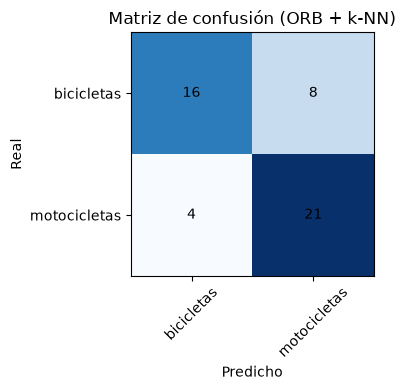

In [23]:
# Función para entrenar, evaluar y graficar la matriz de confusión
def evaluar_knn(X_tr, X_te, nombre, k=5):
    knn = KNeighborsClassifier(n_neighbors=k, metric="euclidean")
    knn.fit(X_tr, y_train)
    pred = knn.predict(X_te)

    acc = accuracy_score(y_test, pred)
    print(f"Accuracy {nombre} + k-NN (k={k}): {acc*100:.2f}%")
    print("\nReporte de clasificación:\n", classification_report(y_test, pred))

    cm = confusion_matrix(y_test, pred, labels=classes)
    plt.figure(figsize=(4, 4))
    plt.imshow(cm, cmap="Blues")
    plt.title(f"Matriz de confusión ({nombre} + k-NN)")
    plt.xticks(range(len(classes)), classes, rotation=45)
    plt.yticks(range(len(classes)), classes)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    plt.xlabel("Predicho")
    plt.ylabel("Real")
    plt.tight_layout()
    plt.show()
    return acc

acc_knn_sift = evaluar_knn(X[train_idx], X[test_idx], "SIFT", k=5)
acc_knn_orb  = evaluar_knn(X_orb[train_idx], X_orb[test_idx], "ORB", k=5)

Accuracy ORB + SVM lineal: 73.47%

Reporte de clasificación:
               precision    recall  f1-score   support

  bicicletas       0.74      0.71      0.72        24
motocicletas       0.73      0.76      0.75        25

    accuracy                           0.73        49
   macro avg       0.73      0.73      0.73        49
weighted avg       0.73      0.73      0.73        49



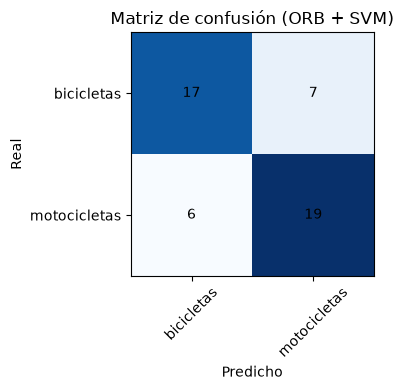

In [24]:
X_train_orb = X_orb[train_idx]
X_test_orb = X_orb[test_idx]

clf_orb = LinearSVC(C=1.0, random_state=42, max_iter=10000)
clf_orb.fit(X_train_orb, y_train)
y_pred_orb = clf_orb.predict(X_test_orb)

acc_orb = accuracy_score(y_test, y_pred_orb)

print("Accuracy ORB + SVM lineal:", f"{acc_orb*100:.2f}%")
print("\nReporte de clasificación:\n", classification_report(y_test, y_pred_orb))

cm_orb = confusion_matrix(y_test, y_pred_orb, labels=classes)

plt.figure(figsize=(4, 4))
plt.imshow(cm_orb, cmap="Blues")
plt.title("Matriz de confusión (ORB + SVM)")
plt.xticks(range(len(classes)), classes, rotation=45)
plt.yticks(range(len(classes)), classes)

for i in range(cm_orb.shape[0]):
    for j in range(cm_orb.shape[1]):
        plt.text(j, i, cm_orb[i, j], ha="center", va="center")

plt.xlabel("Predicho")
plt.ylabel("Real")
plt.tight_layout()
plt.show()

### Mejor K

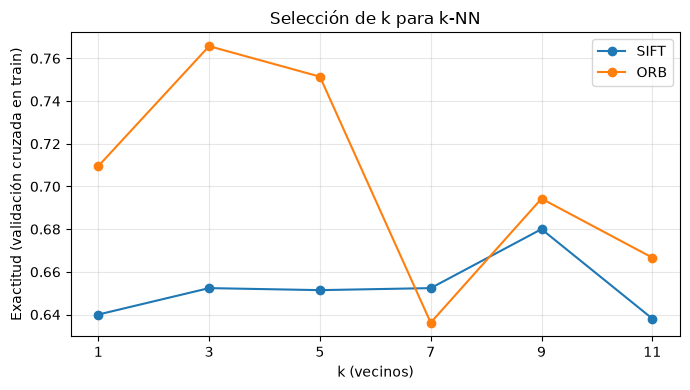

Mejor k SIFT: 9
Mejor k ORB:  3


In [28]:

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
valores_k = [1, 3, 5, 7, 9, 11]

cv_sift, cv_orb = [], []
for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k)
    cv_sift.append(cross_val_score(knn, X[train_idx], y_train, cv=cv).mean())
    cv_orb.append(cross_val_score(knn, X_orb[train_idx], y_train, cv=cv).mean())

plt.figure(figsize=(7, 4))
plt.plot(valores_k, cv_sift, marker="o", label="SIFT")
plt.plot(valores_k, cv_orb, marker="o", label="ORB")
plt.xlabel("k (vecinos)")
plt.ylabel("Exactitud (validación cruzada en train)")
plt.title("Selección de k para k-NN")
plt.xticks(valores_k)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Mejor k SIFT:", valores_k[int(np.argmax(cv_sift))])
print("Mejor k ORB: ", valores_k[int(np.argmax(cv_orb))])

## Clasificador con mejor K

Accuracy SIFT + k-NN (k=9): 75.51%

Reporte de clasificación:
               precision    recall  f1-score   support

  bicicletas       0.83      0.62      0.71        24
motocicletas       0.71      0.88      0.79        25

    accuracy                           0.76        49
   macro avg       0.77      0.75      0.75        49
weighted avg       0.77      0.76      0.75        49



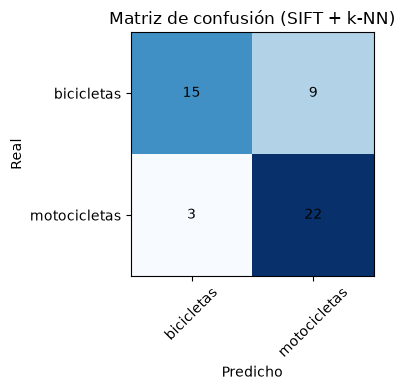

Accuracy ORB + k-NN (k=3): 71.43%

Reporte de clasificación:
               precision    recall  f1-score   support

  bicicletas       0.73      0.67      0.70        24
motocicletas       0.70      0.76      0.73        25

    accuracy                           0.71        49
   macro avg       0.72      0.71      0.71        49
weighted avg       0.72      0.71      0.71        49



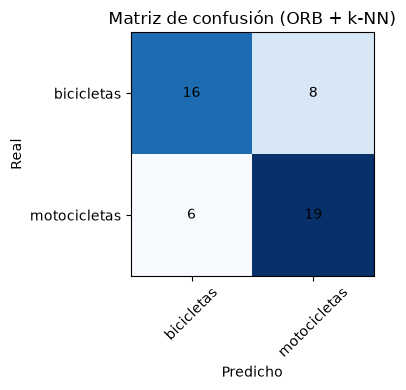

,SVM lineal,k-NN
SIFT,75.51,75.51
ORB,73.47,71.43


In [29]:
k_sift = valores_k[int(np.argmax(cv_sift))]
k_orb  = valores_k[int(np.argmax(cv_orb))]

acc_knn_sift = evaluar_knn(X[train_idx], X[test_idx], "SIFT", k=k_sift)
acc_knn_orb  = evaluar_knn(X_orb[train_idx], X_orb[test_idx], "ORB", k=k_orb)

resumen = pd.DataFrame({
    "SVM lineal": [accuracy_score(y_test, y_pred), accuracy_score(y_test, y_pred_orb)],
    "k-NN":       [acc_knn_sift, acc_knn_orb]
}, index=["SIFT", "ORB"]).round(4) * 100

resumen